# Suivi de performance d'une éolienne : détection des sous-performances et estimation des pertes d'énergie

**Objectif** : à partir des données SCADA d'une éolienne (mesures toutes les 10 minutes sur l'année 2018), détecter les périodes où elle produit moins que prévu, estimer l'énergie perdue et identifier les épisodes les plus coûteux.

**Données** : [Wind Turbine Scada Dataset](https://www.kaggle.com/datasets/berkerisen/wind-turbine-scada-dataset) (Kaggle), une éolienne en Turquie, 5 colonnes : date, puissance active (kW), vitesse du vent (m/s), puissance théorique du fabricant (kW) et direction du vent (°).

**Méthode** : pipeline PySpark sur Databricks en architecture médaillon.

| Couche | Table | Contenu |
| --- | --- | --- |
| Bronze | `bronze_scada` | données brutes, sans modification |
| Silver | `silver_scada` | données nettoyées et annotées (drapeaux d'anomalies, trous) |
| Gold | `gold_pertes_mensuelles`, `gold_episodes_anomalies` | pertes d'énergie par mois et par épisode |

In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt

# Paramètres du projet
SEUIL = 0.7                 # sous-performance : moins de 70 % de la puissance théorique
DUREE_MIN = 6               # durée minimale d'un épisode : 6 mesures x 10 min = 1 heure
CUT_IN = 3.0                # vitesse de démarrage (m/s), vérifiée en section 3
VITESSE_NOMINALE = 13.0     # vitesse nominale (m/s), vérifiée en section 3
PUISSANCE_NOMINALE = 3600   # puissance nominale (kW), vérifiée en section 3

## 1. Bronze : données brutes

Le fichier CSV est importé tel quel dans la table Delta `bronze_scada`. Aucune transformation n'est appliquée, pour toujours pouvoir repartir de l'original.

In [0]:
# Création de la table bronze (à exécuter une seule fois)
(
    spark.read.csv("/Volumes/workspace/default/donnees/T1.csv", header=True, inferSchema=True)
    .write.mode("overwrite").saveAsTable("bronze_scada")
)

In [0]:
bronze = spark.read.table("workspace.default.bronze_scada")
display(bronze.limit(10))

Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
01 01 2018 00:00,380.047790527343,5.31133604049682,416.328907824861,259.994903564453
01 01 2018 00:10,453.76919555664,5.67216682434082,519.917511061494,268.64111328125
01 01 2018 00:20,306.376586914062,5.21603679656982,390.900015810951,272.564788818359
01 01 2018 00:30,419.645904541015,5.65967416763305,516.127568975674,271.258087158203
01 01 2018 00:40,380.650695800781,5.57794094085693,491.702971953588,265.674285888671
01 01 2018 00:50,402.391998291015,5.60405206680297,499.436385024805,264.57861328125
01 01 2018 01:00,447.605712890625,5.79300785064697,557.372363290225,266.163604736328
01 01 2018 01:10,387.2421875,5.30604982376098,414.898178826186,257.949493408203
01 01 2018 01:20,463.651214599609,5.58462905883789,493.677652137077,253.480697631835
01 01 2018 01:30,439.725708007812,5.52322816848754,475.706782818068,258.72378540039


## 2. Silver : nettoyage et annotation

Transformations appliquées :

- **Renommage** des colonnes et **conversion de la date** (texte `dd MM yyyy HH:mm` → timestamp).
- **Puissances négatives ramenées à 0** : elles correspondent à la consommation propre de l'éolienne à l'arrêt (électronique, orientation, chauffage), pas à une production.
- **`ecart_min`** : temps écoulé depuis la mesure précédente. Normalement 10 minutes ; au-delà, il manque des données.
- **Drapeaux d'anomalie** (1 = oui, 0 = non) :
    - `arret` : puissance nulle alors que la puissance théorique est positive ;
    - `sous_perf` : puissance positive mais inférieure à **70 %** de la puissance théorique ;
    - `apres_trou` : première mesure après une interruption des données.
- **`flag`** : la cause de l'anomalie en texte (`arret` ou `sous-perf`).

Les lignes anormales sont **signalées, pas supprimées** : ce sont précisément elles que l'on analyse ensuite.

Contrôles préalables : **aucune date manquante ni doublon** dans les données.

In [0]:
w = Window.orderBy("date")

silver = (
    bronze.select(
        F.to_timestamp(F.col("Date/Time"), "dd MM yyyy HH:mm").alias("date"),
        F.col("LV ActivePower (kW)").alias("puissance"),
        F.col("Wind Speed (m/s)").alias("vent"),
        F.col("Theoretical_Power_Curve (KWh)").alias("puissance_theorique"),
        F.col("Wind Direction (°)").alias("direction"),
    )
    .withColumn("ecart_min",
        (F.col("date").cast("long") - F.lag("date", 1).over(w).cast("long")) / 60)
    .withColumn("puissance", F.greatest(F.col("puissance"), F.lit(0)))
    .withColumn("arret",
        ((F.col("puissance") == 0) & (F.col("puissance_theorique") > 0)).cast("int"))
    .withColumn("sous_perf",
        ((F.col("puissance") > 0) &
         (F.col("puissance") < SEUIL * F.col("puissance_theorique"))).cast("int"))
    .withColumn("apres_trou",
        F.coalesce((F.col("ecart_min") > 10).cast("int"), F.lit(0)))
    .withColumn("flag",
        F.when(F.col("arret") == 1, "arret")
         .when(F.col("sous_perf") == 1, "sous-perf"))
    .withColumn("mois", F.month("date"))
)
silver.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable("silver_scada")

display(silver.limit(10))

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


date,puissance,vent,puissance_theorique,direction,ecart_min,arret,sous_perf,apres_trou,flag,mois
2018-01-01T00:00:00.000Z,380.047790527343,5.31133604049682,416.328907824861,259.994903564453,null,0,0,0,null,1
2018-01-01T00:10:00.000Z,453.76919555664,5.67216682434082,519.917511061494,268.64111328125,10.0,0,0,0,null,1
2018-01-01T00:20:00.000Z,306.376586914062,5.21603679656982,390.900015810951,272.564788818359,10.0,0,0,0,null,1
2018-01-01T00:30:00.000Z,419.645904541015,5.65967416763305,516.127568975674,271.258087158203,10.0,0,0,0,null,1
2018-01-01T00:40:00.000Z,380.650695800781,5.57794094085693,491.702971953588,265.674285888671,10.0,0,0,0,null,1
2018-01-01T00:50:00.000Z,402.391998291015,5.60405206680297,499.436385024805,264.57861328125,10.0,0,0,0,null,1
2018-01-01T01:00:00.000Z,447.605712890625,5.79300785064697,557.372363290225,266.163604736328,10.0,0,0,0,null,1
2018-01-01T01:10:00.000Z,387.2421875,5.30604982376098,414.898178826186,257.949493408203,10.0,0,0,0,null,1
2018-01-01T01:20:00.000Z,463.651214599609,5.58462905883789,493.677652137077,253.480697631835,10.0,0,0,0,null,1
2018-01-01T01:30:00.000Z,439.725708007812,5.52322816848754,475.706782818068,258.72378540039,10.0,0,0,0,null,1


## 3. Contrôles qualité

### Nombre de mesures en anomalie

| Indicateur | Mesures | Équivalent |
| --- | --- | --- |
| Arrêts | 3 514 | environ 586 h |
| Sous-performances (< 70 %) | 3 250 | environ 542 h |
| Interruptions de données | 32 | – |

Ces chiffres comptent toutes les mesures anormales, y compris les baisses très brèves. Seuls les épisodes d'au moins 1 heure seront retenus pour le calcul des pertes (section 6).

In [0]:
%sql
SELECT
  SUM(arret) AS nb_arret,
  SUM(sous_perf) AS nb_sous_perf,
  SUM(apres_trou) AS nb_trous
FROM silver_scada

nb_arret,nb_sous_perf,nb_trous
3514,3250,32


### Interruptions des données

Les 32 interruptions se répartissent en :

- **3 coupures d'environ 4 jours** : fin janvier (104 h), début octobre (91 h) et mi-novembre (87 h) ;
- une quinzaine de coupures de 1 à 12 heures ;
- une douzaine de micro-coupures d'une seule mesure (20 minutes d'écart).

Ces périodes ne sont **ni comblées ni comptées comme des pertes** : on ne sait pas ce qui s'y est passé. Un trou de données ne signifie pas que l'éolienne était arrêtée.

In [0]:
%sql
SELECT date AS fin_du_trou, ROUND(ecart_min / 60, 1) AS heures_ecart
FROM silver_scada
WHERE ecart_min > 10
ORDER BY ecart_min DESC

fin_du_trou,heures_ecart
2018-01-30T14:40:00.000Z,104.3
2018-10-02T16:30:00.000Z,91.2
2018-11-14T12:00:00.000Z,86.8
2018-10-03T06:30:00.000Z,12.3
2018-10-03T14:10:00.000Z,7.5
2018-06-04T13:10:00.000Z,6.5
2018-06-27T14:00:00.000Z,5.3
2018-08-17T10:10:00.000Z,3.8
2018-10-30T14:30:00.000Z,3.5
2018-01-04T12:40:00.000Z,3.0


### Carte d'identité de l'éolienne

Les seuils de fonctionnement sont déduits des données plutôt que supposés :

In [0]:
%sql
SELECT
  MIN(CASE WHEN puissance_theorique > 0 THEN vent END) AS cut_in,
  MIN(CASE WHEN puissance_theorique = (SELECT MAX(puissance_theorique) FROM silver_scada)
           THEN vent END) AS vitesse_nominale,
  MAX(puissance_theorique) AS puissance_nominale,
  MAX(vent) AS vent_max
FROM silver_scada

cut_in,vitesse_nominale,puissance_nominale,vent_max
3.00068402290344,13.000690460205,3600.0,25.2060108184814


| Caractéristique | Valeur |
| --- | --- |
| Vitesse de démarrage (cut-in) | **3,0 m/s** |
| Vitesse nominale | **13,0 m/s** |
| Puissance nominale | **3 600 kW** |

Au-dessus de 13 m/s, l'éolienne plafonne à 3 600 kW.

### Complétude des données par mois

Une journée complète contient 144 mesures (une toutes les 10 minutes).

In [0]:
completude = (
    silver
    .groupBy(F.month("date").alias("mois"))
    .agg(
        F.count("*").alias("nb_mesures"),
        F.max(F.dayofmonth(F.last_day("date"))).alias("nb_jours")
    )
    .withColumn("nb_attendu", F.col("nb_jours") * 144)
    .withColumn("nb_manquant", F.col("nb_attendu") - F.col("nb_mesures"))
    .withColumn("completude_pct", F.round(100 * F.col("nb_mesures") / F.col("nb_attendu"), 1))
    .orderBy("mois")
)
display(completude)

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


mois,nb_mesures,nb_jours,nb_attendu,nb_manquant,completude_pct
1,3817,31,4464,647,85.5
2,4032,28,4032,0,100.0
3,4463,31,4464,1,100.0
4,4305,30,4320,15,99.7
5,4449,31,4464,15,99.7
6,4245,30,4320,75,98.3
7,4464,31,4464,0,100.0
8,4425,31,4464,39,99.1
9,4000,30,4320,320,92.6
10,4083,31,4464,381,91.5


Les données couvrent **96,1 % de l'année** (50 530 mesures sur 52 560 attendues). Les mois les moins complets sont **janvier (85,5 %)**, **novembre (88,0 %)**, octobre (91,5 %) et septembre (92,6 %), à cause des coupures identifiées plus haut. Février, mars et juillet sont complets.

Les valeurs brutes en MWh de ces mois sont donc sous-estimées ; les **ratios** (réel / théorique) restent comparables d'un mois à l'autre.

## 4. Exploration

### Distribution des vitesses de vent

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


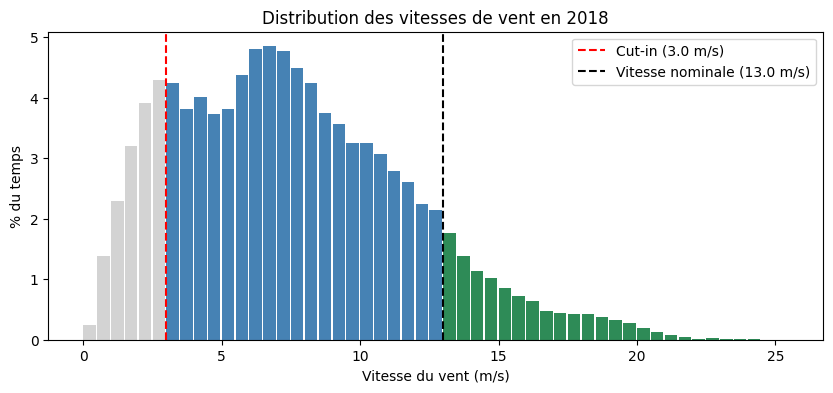

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


+---------------+----------------------+----------+
|pct_sous_cut_in|pct_au_dessus_nominale|vent_moyen|
+---------------+----------------------+----------+
|           15.3|                  10.8|      7.56|
+---------------+----------------------+----------+



In [0]:
total = silver.count()

distribution = (
    silver
    .withColumn("vent_bin", F.floor(F.col("vent") * 2) / 2)
    .groupBy("vent_bin")
    .agg(F.count("*").alias("nb_mesures"))
    .withColumn("pct", F.round(100 * F.col("nb_mesures") / total, 2))
    .orderBy("vent_bin")
)

pdf = distribution.toPandas()
couleurs = ["lightgray" if v < CUT_IN else "seagreen" if v >= VITESSE_NOMINALE else "steelblue"
            for v in pdf["vent_bin"]]

plt.figure(figsize=(10, 4))
plt.bar(pdf["vent_bin"], pdf["pct"], width=0.45, align="edge", color=couleurs)
plt.axvline(CUT_IN, color="red", linestyle="--", label=f"Cut-in ({CUT_IN} m/s)")
plt.axvline(VITESSE_NOMINALE, color="black", linestyle="--", label=f"Vitesse nominale ({VITESSE_NOMINALE} m/s)")
plt.xlabel("Vitesse du vent (m/s)")
plt.ylabel("% du temps")
plt.title("Distribution des vitesses de vent en 2018")
plt.legend()
plt.savefig("distribution_vent.png", dpi=150, bbox_inches="tight")
plt.show()

silver.select(
    F.round(100 * F.avg((F.col("vent") < CUT_IN).cast("int")), 1).alias("pct_sous_cut_in"),
    F.round(100 * F.avg((F.col("vent") >= VITESSE_NOMINALE).cast("int")), 1).alias("pct_au_dessus_nominale"),
    F.round(F.avg("vent"), 2).alias("vent_moyen"),
).show()

- Le vent est **sous le cut-in pendant 15,3 % du temps** (barres grises) : l'éolienne ne peut pas produire, et ces périodes ne sont pas des pertes.
- Les vents les plus fréquents se situent **entre 6 et 8 m/s**, dans la zone où la production augmente fortement avec le vent.
- Le vent dépasse la vitesse nominale **10,8 % du temps** (barres vertes) : l'éolienne y tourne à pleine puissance.
- Le vent moyen sur l'année est de **7,6 m/s**.


### Production mensuelle : réelle vs théorique

In [0]:
par_mois = (
    silver.groupBy("mois")
    .agg(
        F.round(F.sum("puissance") / 6 / 1000, 1).alias("energie_reelle_mwh"),
        F.round(F.sum("puissance_theorique") / 6 / 1000, 1).alias("energie_theorique_mwh"),
    )
    .withColumn("ecart_mwh",
        F.round(F.col("energie_theorique_mwh") - F.col("energie_reelle_mwh"), 1))
    .withColumn("ratio_pct",
        F.round(100 * F.col("energie_reelle_mwh") / F.col("energie_theorique_mwh"), 1))
    .orderBy("mois")
)
display(par_mois)

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


mois,energie_reelle_mwh,energie_theorique_mwh,ecart_mwh,ratio_pct
1,841.7,1175.2,333.5,71.6
2,1010.3,1150.9,140.6,87.8
3,1452.3,1544.1,91.8,94.1
4,591.5,685.7,94.2,86.3
5,620.6,712.0,91.4,87.2
6,704.3,806.0,101.7,87.4
7,354.9,434.3,79.4,81.7
8,1458.9,1637.7,178.8,89.1
9,953.0,1035.5,82.5,92.0
10,958.3,1044.0,85.7,91.8


Sur l'année, l'éolienne a produit **11 013 MWh** pour **12 567 MWh** attendus d'après la courbe du fabricant, soit **87,6 %** de son potentiel.

- Meilleur mois : **mars (94,1 %)**.
- Mois les plus faibles : **janvier (71,6 %)**, juillet (81,7 %) et décembre (82,6 %).

Cet écart brut de 1 554 MWh inclut aussi la dispersion normale entre production réelle et courbe théorique. La perte réellement due aux anomalies est calculée dans la section suivante.

## 5. Gold : détection des épisodes d'anomalie

Méthode :

1. Chaque mesure en arrêt ou en sous-performance est marquée comme **anomalie**.
2. Les anomalies qui se suivent forment un **épisode**. Un épisode est coupé par une interruption des données : on ne relie pas deux anomalies séparées par plusieurs jours sans mesure.
3. Seuls les épisodes d'**au moins 1 heure** (6 mesures) sont retenus, pour écarter les baisses brèves (rafales, bruit de mesure).
4. Pour chaque mesure retenue, l'**énergie perdue** vaut (puissance théorique − puissance réelle) × 10 min, convertie en MWh.

In [0]:
w_cumul = w.rowsBetween(Window.unboundedPreceding, 0)

gold_base = (
    spark.read.table("silver_scada")
    .withColumn("anomalie", F.col("flag").isNotNull().cast("int"))
    # Début d'épisode : anomalie après une mesure normale, ou juste après un trou
    .withColumn("anomalie_prec", F.coalesce(F.lag("anomalie").over(w), F.lit(0)))
    .withColumn("debut_episode",
        ((F.col("anomalie") == 1) &
         ((F.col("anomalie_prec") == 0) | (F.col("apres_trou") == 1))).cast("int"))
    .withColumn("episode_id", F.sum("debut_episode").over(w_cumul))
    # Épisodes d'au moins 1 heure et énergie perdue (MWh)
    .withColumn("duree_episode",
        F.count("*").over(Window.partitionBy("episode_id", "anomalie")))
    .withColumn("anomalie_confirmee",
        ((F.col("anomalie") == 1) & (F.col("duree_episode") >= DUREE_MIN)).cast("int"))
    .withColumn("perte_mwh",
        F.when(F.col("anomalie_confirmee") == 1,
               F.greatest(F.col("puissance_theorique") - F.col("puissance"), F.lit(0)) / 6 / 1000)
         .otherwise(0.0))
)

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


## 6. Pertes d'énergie par mois

In [0]:
gold_mois = (
    gold_base.groupBy("mois")
    .agg(
        F.round(F.sum("puissance_theorique") / 6 / 1000, 1).alias("energie_theorique_mwh"),
        F.round(F.sum("puissance") / 6 / 1000, 1).alias("energie_reelle_mwh"),
        F.round(F.sum(F.when(F.col("flag") == "arret", F.col("perte_mwh")).otherwise(0)), 1).alias("perte_arret_mwh"),
        F.round(F.sum(F.when(F.col("flag") == "sous-perf", F.col("perte_mwh")).otherwise(0)), 1).alias("perte_sous_perf_mwh"),
        F.round(F.sum("perte_mwh"), 1).alias("perte_totale_mwh"),
        F.round(F.sum("anomalie_confirmee") / 6, 1).alias("heures_anomalie"),
    )
    .withColumn("perte_pct",
        F.round(100 * F.col("perte_totale_mwh") / F.col("energie_theorique_mwh"), 1))
    .orderBy("mois")
)
gold_mois.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable("gold_pertes_mensuelles")
display(gold_mois)

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


mois,energie_theorique_mwh,energie_reelle_mwh,perte_arret_mwh,perte_sous_perf_mwh,perte_totale_mwh,heures_anomalie,perte_pct
1,1175.2,841.7,219.3,79.7,299.0,145.3,25.4
2,1150.9,1010.3,77.0,27.9,104.8,71.5,9.1
3,1544.1,1452.3,15.2,3.6,18.8,43.7,1.2
4,685.7,591.5,22.4,3.8,26.2,64.7,3.8
5,712.0,620.6,4.6,1.3,5.9,30.2,0.8
6,806.0,704.3,0.2,1.2,1.3,17.8,0.2
7,434.3,354.9,2.1,2.1,4.2,45.5,1.0
8,1637.7,1458.9,7.2,1.2,8.4,7.3,0.5
9,1035.5,953.0,0.0,1.3,1.4,17.3,0.1
10,1044.0,958.3,0.0,0.4,0.5,4.7,0.0


Les anomalies confirmées représentent **647 MWh perdus sur l'année, soit 5,2 % de l'énergie théorique**, pour environ 645 heures d'anomalie.

- **Par cause** : les **arrêts** expliquent **428 MWh (66 %)**, les sous-performances **219 MWh (34 %)**.
- **Par saison** : **janvier (299 MWh, 25,4 %)**, **décembre (155 MWh, 14,7 %)** et **février (105 MWh, 9,1 %)** concentrent **86 % des pertes de l'année**. De juin à octobre, les pertes restent inférieures à 1 %.

Cette concentration en hiver suggère une cause saisonnière, comme le **givrage des pales** ou une maintenance planifiée en période froide. Le dataset ne contient ni température ni alarmes : cette hypothèse reste à vérifier.

## 7. Épisodes les plus coûteux

In [0]:
gold_episodes = (
    gold_base.filter(F.col("anomalie_confirmee") == 1)
    .groupBy("episode_id")
    .agg(
        F.min("date").alias("debut"),
        F.max("date").alias("fin"),
        F.round(F.count("*") / 6, 1).alias("duree_h"),
        F.round(F.avg("vent"), 1).alias("vent_moy"),
        F.round(100 * F.avg((F.col("flag") == "arret").cast("int")), 0).alias("part_arret_pct"),
        F.round(F.sum("perte_mwh"), 2).alias("perte_mwh"),
    )
    .orderBy(F.col("perte_mwh").desc())
)
gold_episodes.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable("gold_episodes_anomalies")
display(gold_episodes)

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


episode_id,debut,fin,duree_h,vent_moy,part_arret_pct,perte_mwh
72,2018-01-22T19:30:00.000Z,2018-01-26T02:40:00.000Z,79.3,9.5,70.0,170.26
190,2018-02-25T00:30:00.000Z,2018-02-26T10:20:00.000Z,34.0,8.6,48.0,59.94
56,2018-01-13T21:00:00.000Z,2018-01-15T06:30:00.000Z,33.7,9.7,65.0,59.43
1653,2018-12-25T06:50:00.000Z,2018-12-26T17:30:00.000Z,34.8,8.1,38.0,51.82
1595,2018-12-04T21:40:00.000Z,2018-12-05T13:20:00.000Z,15.8,9.9,99.0,34.51
64,2018-01-16T01:10:00.000Z,2018-01-16T10:30:00.000Z,9.5,14.3,93.0,33.33
1638,2018-12-19T08:20:00.000Z,2018-12-20T08:50:00.000Z,24.7,7.3,59.0,25.68
183,2018-02-23T06:00:00.000Z,2018-02-23T14:30:00.000Z,8.7,9.4,96.0,20.52
1676,2018-12-29T07:50:00.000Z,2018-12-30T06:00:00.000Z,22.3,5.9,80.0,16.87
1564,2018-11-30T12:30:00.000Z,2018-12-01T10:30:00.000Z,22.2,6.4,45.0,15.39


**183 épisodes** d'au moins 1 heure ont été détectés. Les plus coûteux :

| Période | Durée | Vent moyen | Part d'arrêt | Perte |
| --- | --- | --- | --- | --- |
| 22 – 26 janvier | 79 h | 9,5 m/s | 70 % | **170 MWh** |
| 25 – 26 février | 34 h | 8,6 m/s | 48 % | 60 MWh |
| 13 – 15 janvier | 34 h | 9,7 m/s | 65 % | 59 MWh |
| 25 – 26 décembre | 35 h | 8,1 m/s | 38 % | 52 MWh |
| 4 – 5 décembre | 16 h | 9,9 m/s | 99 % | 35 MWh |

- L'épisode du **22 au 26 janvier représente à lui seul 26 % des pertes de l'année**. Le vent était soutenu (9,5 m/s) : l'éolienne aurait dû produire.
- Un épisode à **près de 100 % d'arrêt** (4 – 5 décembre) ressemble à une panne ou à une maintenance.
- Un épisode **mixte** (25 – 26 décembre, 38 % d'arrêt) alterne arrêts et production réduite, ce qui est compatible avec du givre ou un bridage.

Ce classement permet à un exploitant de **prioriser les diagnostics** sur les quelques épisodes qui coûtent le plus.

## 8. Modèle de comportement normal (MLlib)

La courbe du fabricant est mesurée en conditions standard et ne connaît pas les conditions réelles du site (turbulence, densité de l'air, effet de la direction du vent). On entraîne donc un modèle qui apprend **comment cette éolienne produit quand elle fonctionne normalement**, pour vérifier si la courbe du fabricant est une bonne référence et, sinon, la remplacer.

Démarche :

1. **Entraîner uniquement sur les mesures normales** (sans arrêt ni sous-performance), pour que le modèle n'apprenne pas les pannes comme un comportement normal.
2. **Valider sur des mois non vus** : entraînement de janvier à septembre, test d'octobre à décembre.
3. **Comparer** la précision du modèle à celle de la courbe du fabricant sur les mêmes mesures.
4. **Recalculer les pertes** des mêmes épisodes avec cette nouvelle référence.

In [0]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

# La direction est un angle (359° est voisin de 1°) : on la transforme en sinus et cosinus
ml_base = (
    spark.read.table("silver_scada")
    .withColumn("dir_sin", F.sin(F.radians("direction")))
    .withColumn("dir_cos", F.cos(F.radians("direction")))
)

normal = ml_base.filter(F.col("flag").isNull())
train = normal.filter(F.col("mois") <= 9)
test = normal.filter(F.col("mois") >= 10)
print("Entraînement :", train.count(), "mesures | Test :", test.count(), "mesures")

Entraînement : 33060 mesures | Test : 10706 mesures


### Entraînement

Le pipeline enchaîne deux étapes :

- `VectorAssembler` rassemble les variables d'entrée (vent, sinus et cosinus de la direction) dans une seule colonne `features`, le format attendu par MLlib ;
- `RandomForestRegressor` apprend à prédire la puissance : 50 arbres de décision dont on fait la moyenne.

Deux réglages sont essentiels : `featureSubsetStrategy="all"` (par défaut, chaque division ne voit qu'une variable sur trois et ignore souvent le vent) et `maxBins=128` (découpage du vent assez fin pour suivre la courbe).

In [0]:
assembler = VectorAssembler(
    inputCols=["vent", "dir_sin", "dir_cos"],
    outputCol="features",
    handleInvalid="skip",
)
foret = RandomForestRegressor(
    featuresCol="features",
    labelCol="puissance",
    numTrees=50,
    maxDepth=10,
    maxBins=128,
    featureSubsetStrategy="all",
    minInstancesPerNode=5,
    seed=42,
)
pipeline = Pipeline(stages=[assembler, foret])

modele_validation = pipeline.fit(train)
pred_train = modele_validation.transform(train)
pred_test = modele_validation.transform(test)

### Évaluation

- **MAE** : erreur absolue moyenne en kW ;
- **RMSE** : erreur moyenne qui pénalise fortement les grosses erreurs ;
- **R²** : part de la variation de la puissance expliquée (1 = parfait).

La courbe du fabricant est évaluée de la même façon, en la traitant comme une « prédiction ». Comparer l'erreur d'entraînement et de test permet aussi de vérifier l'absence de surapprentissage.

In [0]:
def evaluer(df, colonne_prediction):
    resultats = {}
    for metrique in ["mae", "rmse", "r2"]:
        ev = RegressionEvaluator(labelCol="puissance",
                                 predictionCol=colonne_prediction,
                                 metricName=metrique)
        resultats[metrique] = round(ev.evaluate(df), 3)
    return resultats

comparaison = spark.createDataFrame([
    ("Modèle - entraînement (janv.-sept.)", *evaluer(pred_train, "prediction").values()),
    ("Modèle - test (oct.-déc.)", *evaluer(pred_test, "prediction").values()),
    ("Courbe du fabricant - test (oct.-déc.)", *evaluer(pred_test, "puissance_theorique").values()),
], ["reference", "mae_kw", "rmse_kw", "r2"])
display(comparaison)

reference,mae_kw,rmse_kw,r2
Modèle - entraînement (janv.-sept.),55.578,88.81,0.995
Modèle - test (oct.-déc.),77.634,119.515,0.991
Courbe du fabricant - test (oct.-déc.),117.496,183.551,0.98


| Référence | MAE | RMSE | R² |
| --- | --- | --- | --- |
| Modèle, entraînement | 56 kW | 89 kW | 0,995 |
| **Modèle, test** | **78 kW** | **120 kW** | **0,991** |
| Courbe du fabricant, test | 117 kW | 184 kW | 0,980 |

- Sur des mois jamais vus, le modèle fait **environ un tiers d'erreur en moins** que la courbe du fabricant.
- L'écart entre entraînement (56 kW) et test (78 kW) reste modéré : **pas de surapprentissage marqué**. Une partie de l'écart vient peut-être du changement de saison entre les deux périodes.

### La direction du vent apporte-t-elle quelque chose ?

La direction pourrait servir d'indice indirect de la saison plutôt que pour son effet physique. On compare avec un modèle utilisant **le vent seul** : si l'erreur reste proche, le modèle le plus simple est préférable.

In [0]:
assembler_vent = VectorAssembler(inputCols=["vent"], outputCol="features", handleInvalid="skip")
pipeline_vent = Pipeline(stages=[assembler_vent, foret])
pred_test_vent = pipeline_vent.fit(train).transform(test)

print("Vent + direction :", evaluer(pred_test, "prediction"))
print("Vent seul        :", evaluer(pred_test_vent, "prediction"))

Vent + direction : {'mae': 77.634, 'rmse': 119.515, 'r2': 0.991}
Vent seul        : {'mae': 82.04, 'rmse': 128.321, 'r2': 0.99}


| Modèle (test oct.–déc.) | MAE | RMSE | R² |
| --- | --- | --- | --- |
| Vent + direction | **77,6 kW** | **119,5 kW** | 0,991 |
| Vent seul | 82,0 kW | 128,3 kW | 0,990 |

La direction réduit l'erreur moyenne d'environ **5 %**. Le gain est modeste mais apparaît sur toutes les métriques et sur des mois non vus : on conserve le modèle avec la direction. L'essentiel de la précision vient toutefois du vent, et même le modèle « vent seul » fait nettement mieux que la courbe du fabricant (117 kW).

### Modèle final et courbe de puissance

Une fois la méthode validée, le modèle est réentraîné sur **toutes** les mesures normales de l'année, puis utilisé pour prédire la puissance attendue de **toutes** les mesures, bornée entre 0 et la puissance nominale.

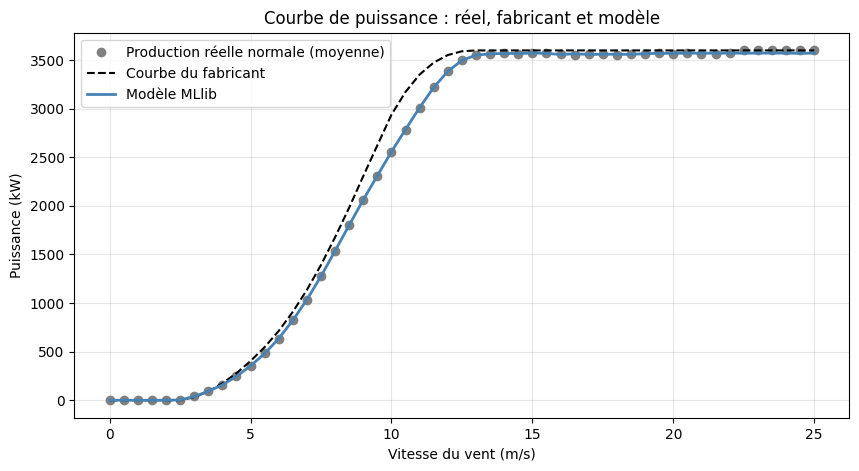

In [0]:
modele = pipeline.fit(normal)

predictions = (
    modele.transform(ml_base)
    .withColumn("puissance_attendue",
        F.least(F.greatest(F.col("prediction"), F.lit(0)), F.lit(PUISSANCE_NOMINALE)))
    .select("date", "puissance_attendue")
)

courbes = (
    modele.transform(normal)
    .withColumn("vent_bin", F.floor(F.col("vent") * 2) / 2)
    .groupBy("vent_bin")
    .agg(
        F.avg("puissance").alias("reelle"),
        F.avg("puissance_theorique").alias("fabricant"),
        F.avg("prediction").alias("modele"),
    )
    .orderBy("vent_bin")
    .toPandas()
)

plt.figure(figsize=(10, 5))
plt.plot(courbes["vent_bin"], courbes["reelle"], "o", color="gray", label="Production réelle normale (moyenne)")
plt.plot(courbes["vent_bin"], courbes["fabricant"], "--", color="black", label="Courbe du fabricant")
plt.plot(courbes["vent_bin"], courbes["modele"], "-", color="steelblue", linewidth=2, label="Modèle MLlib")
plt.xlabel("Vitesse du vent (m/s)")
plt.ylabel("Puissance (kW)")
plt.title("Courbe de puissance : réel, fabricant et modèle")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("courbe_puissance_modele.png", dpi=150, bbox_inches="tight")
plt.show()

Le modèle suit fidèlement la production réelle. La courbe du fabricant est **optimiste entre 7 et 12,5 m/s** : même en fonctionnement normal, l'éolienne y produit moins que prévu, comme si sa courbe était décalée d'environ 0,5 m/s vers la droite.

### Pertes recalculées avec le modèle

On reprend exactement les mêmes épisodes d'anomalie confirmés (section 5) et on calcule la perte avec les deux références. Le modèle n'a jamais vu ces mesures : il n'est entraîné que sur les mesures normales.

In [0]:
pertes_comparees = (
    gold_base
    .join(predictions, on="date", how="left")
    .filter(F.col("anomalie_confirmee") == 1)
    .groupBy("mois")
    .agg(
        F.round(F.sum("perte_mwh"), 1).alias("perte_fabricant_mwh"),
        F.round(F.sum(F.greatest(F.col("puissance_attendue") - F.col("puissance"), F.lit(0)) / 6 / 1000), 1)
            .alias("perte_modele_mwh"),
    )
    .orderBy("mois")
)
display(pertes_comparees)

pertes_comparees.agg(
    F.round(F.sum("perte_fabricant_mwh"), 1).alias("total_fabricant_mwh"),
    F.round(F.sum("perte_modele_mwh"), 1).alias("total_modele_mwh"),
).show()

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


mois,perte_fabricant_mwh,perte_modele_mwh
1,299.0,279.1
2,104.8,91.4
3,18.8,17.2
4,26.2,23.9
5,5.9,5.6
6,1.3,0.9
7,4.2,3.6
8,8.4,7.5
9,1.4,1.0
10,0.5,0.3


+-------------------+----------------+
|total_fabricant_mwh|total_modele_mwh|
+-------------------+----------------+
|              647.3|           593.3|
+-------------------+----------------+



Avec le modèle comme référence, les pertes dues aux anomalies sont estimées à **593 MWh**, contre **647 MWh** avec la courbe du fabricant (**−8 %**). Environ 54 MWh de « pertes » correspondaient donc au comportement normal du site, principalement entre 7 et 12,5 m/s.

## 9. Conclusion

| Indicateur | Valeur |
| --- | --- |
| Couverture des données | 96,1 % de 2018 |
| Production réelle / théorique | 11 013 / 12 567 MWh (87,6 %) |
| Pertes dues aux anomalies (courbe du fabricant) | 647 MWh (5,2 %) |
| Pertes dues aux anomalies (modèle de comportement normal) | 593 MWh |
| Part des arrêts dans les pertes | 66 % |
| Épisode le plus coûteux | 22 – 26 janvier, 170 MWh |
| Précision du modèle (MAE, test) | 78 kW, contre 117 kW pour la courbe du fabricant |

**À retenir** : l'éolienne perd environ **600 MWh par an** à cause d'anomalies d'au moins une heure, dont les deux tiers par des arrêts complets, et presque toutes en hiver. Une poignée d'épisodes concentre l'essentiel des pertes : c'est là qu'un exploitant devrait diagnostiquer en priorité.

### Limites

- **Seuil de 70 % et durée d'1 heure** : choix raisonnables mais arbitraires ; les pertes varient selon ces paramètres.
- **Pas d'alarmes ni de température** : les causes (panne, givre, maintenance, bridage) ne peuvent pas être confirmées.
- **Modèle limité au vent et à sa direction** : la densité de l'air, qui varie d'environ 10 % entre l'hiver et l'été, n'est pas prise en compte.
- **Une seule éolienne**, sur une seule année.

### Pistes d'amélioration

- Ajouter des **données météo** (température, pression) pour tenir compte de la densité de l'air et tester l'hypothèse du **givrage** en hiver.
- Appliquer le pipeline à plusieurs éoliennes.
- **Améliorer la validation du modèle** : l'entraînement (janvier à septembre) et le test (octobre à décembre) portent sur des saisons différentes. Une séparation par semaines alternées ou une validation croisée par mois permettrait de tester le modèle sur toutes les saisons, en évitant la fuite de données liée aux mesures voisines.
